<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/standard_model/sm_ch01_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*The Standard Model* — `sm_ch01_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Standard Model Ch 1 Figures — Colab Notebook
**The Standard Model · Chapter 1: Symmetries**

Tong (DAMTP, Cambridge) · Run each cell to generate figures.
Output: `figures/ch01/fig0N_*.png`

| Figure | Section | Content |
|--------|---------|--------|
| fig01  | §1.1    | Lorentz group representations $(j_+, j_-)$ on the rep diagram |
| fig02  | §1.2    | Weyl, Dirac, and Majorana spinors — chirality and mass structure |
| fig03  | §1.3    | Yang-Mills Feynman vertices: 3-gluon and 4-gluon interactions |

## Setup — dark palette & output directory

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
from matplotlib.patches import FancyArrowPatch, Circle, FancyBboxPatch, Arc
from matplotlib.colors import Normalize, to_rgba
import matplotlib.cm as cm
import matplotlib.lines as mlines
import os

# ── Dark palette (Standard Model series — teal/cyan accent) ───────────────
BG     = '#1e1e2e'
FG     = '#cdd6f4'
EDGE   = '#45475a'
TEAL   = '#2ec4b6'   # Standard Model accent (teal/cyan)
BLUE   = '#7ec8e3'
YELLOW = '#f9c74f'
GREEN  = '#90ee90'
RED    = '#e07070'
PURPLE = '#c792ea'
ORANGE = '#e8a838'

def hex_alpha(hexcol, alpha=0.13):
    """Return an RGBA tuple from a hex colour + alpha — safe for FancyBboxPatch."""
    r, g, b, _ = to_rgba(hexcol)
    return (r, g, b, alpha)

plt.rcParams.update({
    'figure.facecolor'   : BG,
    'axes.facecolor'     : BG,
    'text.color'         : FG,
    'axes.labelcolor'    : FG,
    'xtick.color'        : FG,
    'ytick.color'        : FG,
    'axes.edgecolor'     : EDGE,
    'grid.color'         : EDGE,
    'grid.alpha'         : 0.3,
    'font.size'          : 12,
    'axes.titlesize'     : 13,
    'axes.titleweight'   : 'bold',
    'axes.titlecolor'    : TEAL,
    'legend.framealpha'  : 0.3,
    'legend.edgecolor'   : EDGE,
    'xtick.major.size'   : 4,
    'ytick.major.size'   : 4,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'axes.linewidth'     : 1.2,
    'lines.linewidth'    : 2.2,
    'figure.dpi'         : 110,
})

OUTDIR = 'figures/ch01'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

print('Setup complete. Palette and output directory ready.')


Setup complete. Palette and output directory ready.


---
## fig01 · Lorentz Group Representations $(j_+, j_-)$ (§1.1)

**Left**: The $(j_+, j_-)$ representation lattice — each node labelled by particle type  
**Middle**: $SL(2,\mathbb{C})$ double-cover diagram, connecting $SO^+(1,3)$ to $SU(2)\oplus SU(2)$  
**Right**: Decomposition of tensor products — e.g. $(\tfrac12,0)\otimes(0,\tfrac12) = (\tfrac12,\tfrac12)$

  saved -> figures/ch01/fig01_lorentz_reps.png


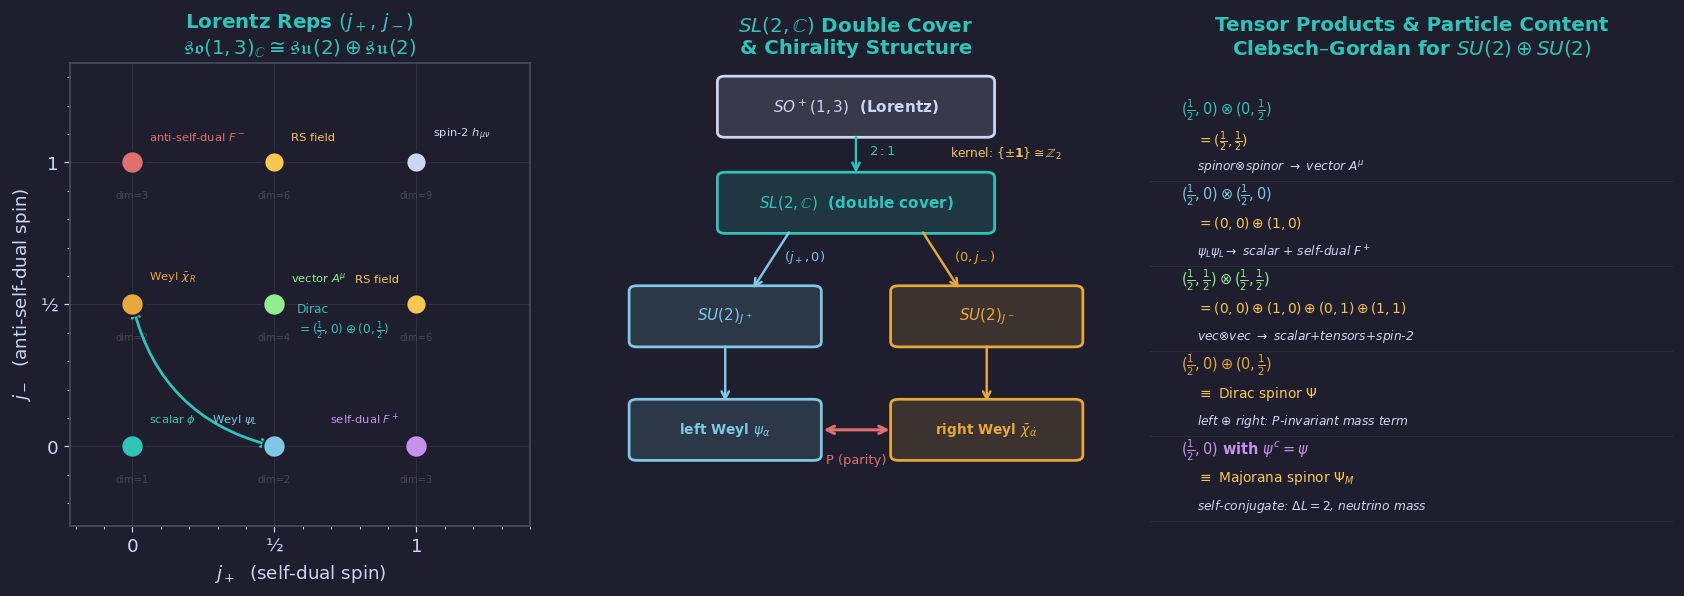

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
fig.patch.set_facecolor(BG)

# ── Left: (j+, j-) representation lattice ─────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)
ax.set_aspect('equal')

# Representations: (j+, j-) -> label, color, size
reps = [
    (0,   0,   r'$(0,0)$'            + '\nscalar $\\phi$',           TEAL,   220),
    (0.5, 0,   r'$(\\frac{1}{2},0)$'  + '\nWeyl $\\psi_L$',          BLUE,   220),
    (0,   0.5, r'$(0,\\frac{1}{2})$'  + '\nWeyl $\\bar\\chi_R$',     ORANGE, 220),
    (0.5, 0.5, r'$(\\frac{1}{2},\\frac{1}{2})$' + '\nvector $A^\\mu$', GREEN,  220),
    (1,   0,   r'$(1,0)$'             + '\nself-dual $F^+$',          PURPLE, 220),
    (0,   1,   r'$(0,1)$'             + '\nanti-self-dual $F^-$',     RED,    220),
    (1,   0.5, r'$(1,\\frac{1}{2})$'  + '\nRS field',                YELLOW, 180),
    (0.5, 1,   r'$(\\frac{1}{2},1)$'  + '\nRS field',                YELLOW, 180),
    (1,   1,   r'$(1,1)$'             + '\nspin-2 $h_{\\mu\\nu}$',    FG,     180),
]

# Draw faint grid
for j in [0, 0.5, 1]:
    ax.axhline(j, color=EDGE, lw=0.7, alpha=0.45, zorder=1)
    ax.axvline(j, color=EDGE, lw=0.7, alpha=0.45, zorder=1)

# Draw nodes
for (jp, jm, lbl, col, sz) in reps:
    dim = int((2*jp+1)*(2*jm+1))
    ax.scatter(jp, jm, s=sz, color=col, zorder=5, edgecolors=BG, linewidth=1.5)
    short = lbl.split('\n')[1] if '\n' in lbl else lbl
    # Alternating label side to avoid overlap on diagonal
    dx = 0.06 if jp <= jm else -0.06
    ha = 'left' if jp <= jm else 'right'
    ax.text(jp + dx, jm + 0.07, short, fontsize=7.5, color=col, va='bottom', ha=ha)
    ax.text(jp, jm - 0.10, f'dim={dim}', fontsize=6.5, color=EDGE, ha='center', va='top')

# Dirac arrow
ax.annotate('', xy=(0.5, 0), xytext=(0, 0.5),
            arrowprops=dict(arrowstyle='<->', color=TEAL, lw=1.8,
                            connectionstyle='arc3,rad=0.3'))
ax.text(0.58, 0.40, 'Dirac\n$= (\\frac{1}{2},0)\\oplus(0,\\frac{1}{2})$',
        fontsize=8, color=TEAL, ha='left')

ax.set_xlim(-0.22, 1.40)
ax.set_ylim(-0.28, 1.35)
ax.set_xlabel(r'$j_+$  (self-dual spin)',  labelpad=5)
ax.set_ylabel(r'$j_-$  (anti-self-dual spin)', labelpad=5)
ax.set_xticks([0, 0.5, 1])
ax.set_xticklabels(['0', '½', '1'])
ax.set_yticks([0, 0.5, 1])
ax.set_yticklabels(['0', '½', '1'])
ax.set_title(r'Lorentz Reps $(j_+,\,j_-)$' + '\n' +
             r'$\mathfrak{so}(1,3)_\mathbb{C}\cong\mathfrak{su}(2)\oplus\mathfrak{su}(2)$',
             color=TEAL)
ax.grid(False)

# ── Middle: SL(2,C) double cover diagram ──────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)
ax2.set_xlim(-0.5, 3.5)
ax2.set_ylim(-0.6, 4.7)
ax2.axis('off')
ax2.set_title(r'$SL(2,\mathbb{C})$ Double Cover' + '\n' +
              r'& Chirality Structure', color=TEAL)

def draw_box(ax, x, y, w, h, label, col, fontsize=10):
    """FancyBboxPatch with proper RGBA fill — avoids broken hex+'22' trick."""
    rect = FancyBboxPatch((x - w/2, y - h/2), w, h,
                          boxstyle='round,pad=0.06',
                          linewidth=1.8, edgecolor=col,
                          facecolor=hex_alpha(col, 0.15))
    ax.add_patch(rect)
    ax.text(x, y, label, ha='center', va='center',
            color=col, fontsize=fontsize, fontweight='bold')

draw_box(ax2, 1.5, 4.2, 2.0, 0.58, r'$SO^+(1,3)$  (Lorentz)', FG, 10)
draw_box(ax2, 1.5, 3.1, 2.0, 0.58, r'$SL(2,\mathbb{C})$  (double cover)', TEAL, 10)
draw_box(ax2, 0.5, 1.8, 1.35, 0.58, r'$SU(2)_{J^+}$', BLUE, 10)
draw_box(ax2, 2.5, 1.8, 1.35, 0.58, r'$SU(2)_{J^-}$', ORANGE, 10)
draw_box(ax2, 0.5, 0.5, 1.35, 0.58, r'left Weyl $\psi_\alpha$', BLUE, 9)
draw_box(ax2, 2.5, 0.5, 1.35, 0.58, r'right Weyl $\bar\chi_{\dot\alpha}$', ORANGE, 9)

def arr(ax, x1, y1, x2, y2, col, label='', lw=1.6):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=col, lw=lw))
    if label:
        mx, my = (x1+x2)/2, (y1+y2)/2
        ax.text(mx + 0.10, my, label, color=col, fontsize=8.5)

arr(ax2, 1.5, 3.89, 1.5, 3.41, TEAL, r'$2:1$')
arr(ax2, 1.0, 2.79, 0.7, 2.09, BLUE,   r'$(j_+,0)$')
arr(ax2, 2.0, 2.79, 2.3, 2.09, ORANGE, r'$(0,j_-)$')
arr(ax2, 0.5, 1.49, 0.5, 0.79, BLUE)
arr(ax2, 2.5, 1.49, 2.5, 0.79, ORANGE)

# Parity arrow
ax2.annotate('', xy=(1.78, 0.5), xytext=(1.23, 0.5),
             arrowprops=dict(arrowstyle='<->', color=RED, lw=2.0))
ax2.text(1.5, 0.12, 'P (parity)', ha='center', color=RED, fontsize=8.5)

# Z2 kernel
ax2.text(2.22, 3.62, r'kernel: $\{\pm\mathbf{1}\}\cong\mathbb{Z}_2$',
         color=YELLOW, fontsize=8)

# ── Right: tensor product decompositions ──────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)
ax3.set_xlim(-0.3, 4.8)
ax3.set_ylim(-0.3, 5.8)
ax3.axis('off')
ax3.set_title('Tensor Products & Particle Content\n' +
              r'Clebsch–Gordan for $SU(2)\oplus SU(2)$', color=TEAL)

# Each entry: (representation, =result, physical meaning, colour)
products = [
    (r'$(\frac{1}{2},0)\otimes(0,\frac{1}{2})$',
     r'$=(\frac{1}{2},\frac{1}{2})$',
     r'spinor$\otimes$spinor $\to$ vector $A^\mu$',
     TEAL),
    (r'$(\frac{1}{2},0)\otimes(\frac{1}{2},0)$',
     r'$=(0,0)\oplus(1,0)$',
     r'$\psi_L\psi_L\to$ scalar $+$ self-dual $F^+$',
     BLUE),
    (r'$(\frac{1}{2},\frac{1}{2})\otimes(\frac{1}{2},\frac{1}{2})$',
     r'$=(0,0)\oplus(1,0)\oplus(0,1)\oplus(1,1)$',
     r'vec$\otimes$vec $\to$ scalar$+$tensors$+$spin-2',
     GREEN),
    (r'$(\frac{1}{2},0)\oplus(0,\frac{1}{2})$',
     r'$\equiv$ Dirac spinor $\Psi$',
     r'left $\oplus$ right: P-invariant mass term',
     ORANGE),
    (r'$(\frac{1}{2},0)$ with $\psi^c=\psi$',
     r'$\equiv$ Majorana spinor $\Psi_M$',
     r'self-conjugate: $\Delta L=2$, neutrino mass',
     PURPLE),
]

y_pos = 5.35
ROW_H = 1.12
for (prod, result, meaning, col) in products:
    ax3.text(0.0, y_pos,        prod,    color=col,    fontsize=9.5, va='top', fontweight='bold')
    ax3.text(0.15, y_pos-0.42,  result,  color=YELLOW,  fontsize=9,   va='top')
    ax3.text(0.15, y_pos-0.80,  meaning, color=FG,       fontsize=8,   va='top', style='italic')
    ax3.axhline(y_pos - ROW_H + 0.02, color=EDGE, lw=0.5, alpha=0.5)
    y_pos -= ROW_H

plt.tight_layout(pad=1.8)
save('fig01_lorentz_reps.png', fig)


---
## fig02 · Weyl, Dirac, and Majorana Spinors (§1.2)

**Left**: Mass terms as arrows connecting chiralities — Dirac vs Majorana structure  
**Middle**: Helicity content of each spinor type; how parity acts  
**Right**: SM fermion assignment — which fields are left/right-handed Weyl spinors

  saved -> figures/ch01/fig02_weyl_dirac_majorana.png


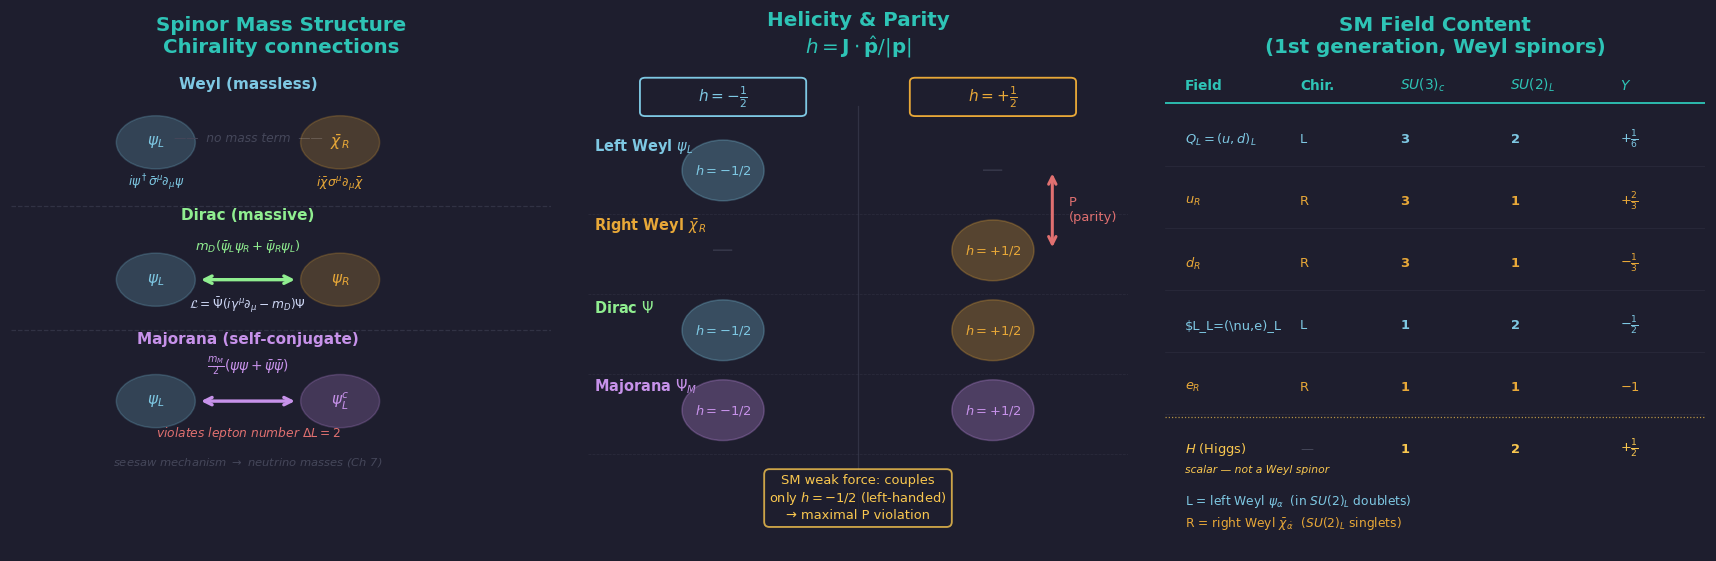

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
fig.patch.set_facecolor(BG)

# ── Left: mass-term connectivity diagram ──────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)
ax.set_xlim(-0.3, 3.8)
ax.set_ylim(-0.5, 5.0)
ax.axis('off')
ax.set_title('Spinor Mass Structure\n' + r'Chirality connections', color=TEAL)

def node(ax, x, y, label, col, r=0.30):
    c = Circle((x, y), r, color=col, alpha=0.22, zorder=3)
    ax.add_patch(c)
    ax.text(x, y, label, ha='center', va='center', color=col,
            fontsize=10, fontweight='bold', zorder=4)

def double_arrow(ax, x1, y1, x2, y2, col, label='', style='<->'):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle=style, color=col, lw=2.2))
    if label:
        mx, my = (x1+x2)/2 + 0.1, (y1+y2)/2
        ax.text(mx, my, label, color=col, fontsize=9, ha='left', va='center')

# --- Weyl (massless) ---
ax.text(1.5, 4.7, 'Weyl (massless)', ha='center', color=BLUE, fontsize=10, fontweight='bold')
node(ax, 0.8, 4.1, r'$\psi_L$', BLUE)
ax.text(1.5, 4.1, r'——  no mass term  ——', ha='center', color=EDGE, fontsize=8, style='italic')
node(ax, 2.2, 4.1, r'$\bar\chi_R$', ORANGE)
ax.text(0.8, 3.60, r'$i\psi^\dagger\bar\sigma^\mu\partial_\mu\psi$',
        ha='center', color=BLUE, fontsize=8)
ax.text(2.2, 3.60, r'$i\bar\chi\sigma^\mu\partial_\mu\bar\chi$',
        ha='center', color=ORANGE, fontsize=8)

ax.axhline(3.38, color=EDGE, lw=0.8, ls='--', alpha=0.5)

# --- Dirac (massive) ---
ax.text(1.5, 3.22, 'Dirac (massive)', ha='center', color=GREEN, fontsize=10, fontweight='bold')
node(ax, 0.8, 2.55, r'$\psi_L$', BLUE)
node(ax, 2.2, 2.55, r'$\psi_R$', ORANGE)
double_arrow(ax, 1.12, 2.55, 1.88, 2.55, GREEN)
ax.text(1.5, 2.88, r'$m_D(\bar\psi_L\psi_R + \bar\psi_R\psi_L)$',
        ha='center', color=GREEN, fontsize=8.5)
ax.text(1.5, 2.22, r'$\mathcal{L}=\bar\Psi(i\gamma^\mu\partial_\mu - m_D)\Psi$',
        ha='center', color=FG, fontsize=8)

ax.axhline(1.98, color=EDGE, lw=0.8, ls='--', alpha=0.5)

# --- Majorana ---
ax.text(1.5, 1.82, 'Majorana (self-conjugate)', ha='center', color=PURPLE, fontsize=10, fontweight='bold')
node(ax, 0.8, 1.18, r'$\psi_L$', BLUE)
node(ax, 2.2, 1.18, r'$\psi_L^c$', PURPLE)
double_arrow(ax, 1.12, 1.18, 1.88, 1.18, PURPLE)
ax.text(1.5, 1.52, r'$\frac{m_M}{2}(\psi\psi + \bar\psi\bar\psi)$',
        ha='center', color=PURPLE, fontsize=9)
ax.text(1.5, 0.78, r'violates lepton number $\Delta L = 2$',
        ha='center', color=RED, fontsize=8, style='italic')
ax.text(1.5, 0.45, r'seesaw mechanism $\to$ neutrino masses (Ch 7)',
        ha='center', color=EDGE, fontsize=7.5, style='italic')

# ── Middle: helicity content & parity — 2-column grid layout ─────────────
ax2 = axes[1]
ax2.set_facecolor(BG)
ax2.set_xlim(0, 5.0)
ax2.set_ylim(-0.3, 5.8)
ax2.axis('off')
ax2.set_title('Helicity & Parity\n' + r'$h = \mathbf{J}\cdot\hat{\mathbf{p}}/|\mathbf{p}|$',
              color=TEAL)

LEFT_X  = 1.25   # fixed x for h = -1/2 column
RIGHT_X = 3.75   # fixed x for h = +1/2 column
COL_MID = (LEFT_X + RIGHT_X) / 2

# Column header boxes
for xc, lbl, col in [(LEFT_X,  r'$h = -\frac{1}{2}$', BLUE),
                      (RIGHT_X, r'$h = +\frac{1}{2}$', ORANGE)]:
    bar = FancyBboxPatch((xc - 0.72, 5.18), 1.44, 0.38,
                         boxstyle='round,pad=0.05',
                         linewidth=1.2, edgecolor=col, facecolor=(0,0,0,0.0))
    ax2.add_patch(bar)
    ax2.text(xc, 5.37, lbl, ha='center', va='center',
             color=col, fontsize=10, fontweight='bold')

# Central vertical separator
ax2.axvline(COL_MID, color=EDGE, lw=0.8, alpha=0.5, ymin=0.08, ymax=0.91)

# Rows: (label, left_filled, right_filled, row_colour, y_centre)
CIRC_R = 0.38
spinor_rows = [
    (r'Left Weyl $\psi_L$',      True,  False, BLUE,   4.45),
    (r'Right Weyl $\bar\chi_R$', False, True,  ORANGE, 3.45),
    (r'Dirac $\Psi$',            True,  True,  GREEN,  2.45),
    (r'Majorana $\Psi_M$',       True,  True,  PURPLE, 1.45),
]

left_weyl_y = None
for (name, has_left, has_right, col, yc) in spinor_rows:
    # Row label
    ax2.text(0.05, yc + 0.18, name, color=col, fontsize=9.5,
             fontweight='bold', va='bottom')

    # Left column (h = -1/2)
    if has_left:
        hcol = BLUE if col != PURPLE else PURPLE
        ax2.add_patch(Circle((LEFT_X, yc), CIRC_R, color=hcol, alpha=0.28, zorder=3))
        ax2.text(LEFT_X, yc, r'$h{=}{-}1/2$', ha='center', va='center',
                 color=hcol, fontsize=8.5, fontweight='bold', zorder=4)
    else:
        ax2.text(LEFT_X, yc, '—', ha='center', va='center',
                 color=EDGE, fontsize=14, alpha=0.6)

    # Right column (h = +1/2)
    if has_right:
        hcol = ORANGE if col != PURPLE else PURPLE
        ax2.add_patch(Circle((RIGHT_X, yc), CIRC_R, color=hcol, alpha=0.28, zorder=3))
        ax2.text(RIGHT_X, yc, r'$h{=}{+}1/2$', ha='center', va='center',
                 color=hcol, fontsize=8.5, fontweight='bold', zorder=4)
    else:
        ax2.text(RIGHT_X, yc, '—', ha='center', va='center',
                 color=EDGE, fontsize=14, alpha=0.6)

    # Parity arrow between Left Weyl and Right Weyl rows
    if name.startswith('Left'):
        left_weyl_y = yc
    if name.startswith('Right') and left_weyl_y is not None:
        ax2.annotate('', xy=(RIGHT_X + 0.55, yc),
                     xytext=(RIGHT_X + 0.55, left_weyl_y),
                     arrowprops=dict(arrowstyle='<->', color=RED, lw=2.0))
        ax2.text(RIGHT_X + 0.70, (left_weyl_y + yc) / 2,
                 'P\n(parity)', color=RED, fontsize=8.5, ha='left', va='center')

    ax2.axhline(yc - 0.55, color=EDGE, lw=0.5, ls='--', alpha=0.35)

# SM note
ax2.text(COL_MID, 0.35,
         'SM weak force: couples\nonly $h=-1/2$ (left-handed)\n→ maximal P violation',
         ha='center', va='center', color=YELLOW, fontsize=8.5,
         bbox=dict(boxstyle='round,pad=0.4', fc=BG, ec=YELLOW, alpha=0.8, lw=1.2))

# ── Right: SM fermion field content ───────────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)
ax3.set_xlim(-0.2, 5.2)
ax3.set_ylim(-0.5, 5.8)
ax3.axis('off')
ax3.set_title('SM Field Content\n(1st generation, Weyl spinors)', color=TEAL)

headers = ['Field', 'Chir.', r'$SU(3)_c$', r'$SU(2)_L$', r'$Y$']
xs      = [0.0, 1.15, 2.15, 3.25, 4.35]
for x, h in zip(xs, headers):
    ax3.text(x, 5.45, h, color=TEAL, fontsize=9, fontweight='bold')
ax3.axhline(5.28, color=TEAL, lw=1.2, xmin=0.0, xmax=1.0)

rows = [
    (r'$Q_L=(u,d)_L$',  'L',  r'$\mathbf{3}$',  r'$\mathbf{2}$',  r'$+\frac{1}{6}$', BLUE),
    (r'$u_R$',           'R',  r'$\mathbf{3}$',  r'$\mathbf{1}$',  r'$+\frac{2}{3}$', ORANGE),
    (r'$d_R$',           'R',  r'$\mathbf{3}$',  r'$\mathbf{1}$',  r'$-\frac{1}{3}$', ORANGE),
    (r'$L_L=(\nu,e)_L','L',  r'$\mathbf{1}$',  r'$\mathbf{2}$',  r'$-\frac{1}{2}$', BLUE),
    (r'$e_R$',           'R',  r'$\mathbf{1}$',  r'$\mathbf{1}$',  r'$-1$',           ORANGE),
]

ROW_H = 0.80
y = 4.80
for (field, chir, su3, su2, Y, col) in rows:
    vals = [field, chir, su3, su2, Y]
    chircolor = BLUE if chir == 'L' else ORANGE
    for j, (x, v) in enumerate(zip(xs, vals)):
        vc = chircolor if j == 1 else col
        ax3.text(x, y, v, color=vc, fontsize=8.5, va='center')
    ax3.axhline(y - ROW_H*0.42, color=EDGE, lw=0.4, alpha=0.4)
    y -= ROW_H

ax3.axhline(y + ROW_H*0.52, color=YELLOW, lw=0.8, ls=':', alpha=0.7)
ax3.text(0.0, y, r'$H$ (Higgs)', color=YELLOW, fontsize=8.5, va='center')
ax3.text(1.15, y, '—',            color=EDGE,   fontsize=8.5, va='center')
ax3.text(2.15, y, r'$\mathbf{1}$',color=YELLOW, fontsize=8.5, va='center')
ax3.text(3.25, y, r'$\mathbf{2}$',color=YELLOW, fontsize=8.5, va='center')
ax3.text(4.35, y, r'$+\frac{1}{2}$',color=YELLOW, fontsize=8.5, va='center')
ax3.text(0.0, y - 0.30,
         r'scalar — not a Weyl spinor',
         color=YELLOW, fontsize=7, style='italic')

ax3.text(0.0, y - 0.72,
         r'L = left Weyl $\psi_\alpha$  (in $SU(2)_L$ doublets)',
         color=BLUE, fontsize=8)
ax3.text(0.0, y - 1.00,
         r'R = right Weyl $\bar\chi_{\dot\alpha}$  ($SU(2)_L$ singlets)',
         color=ORANGE, fontsize=8)

plt.tight_layout(pad=1.8)
save('fig02_weyl_dirac_majorana.png', fig)

---
## fig03 · Yang-Mills Feynman Vertices (§1.3)

**Left**: 3-gluon vertex from $f^{abc}A^b A^c \partial A^a$ — the key non-abelian term  
**Middle**: 4-gluon vertex from $(f^{abe}A^a A^b)^2$  
**Right**: Comparison: QED (abelian, no photon self-coupling) vs QCD (non-abelian)

  saved -> figures/ch01/fig03_yang_mills_vertices.png


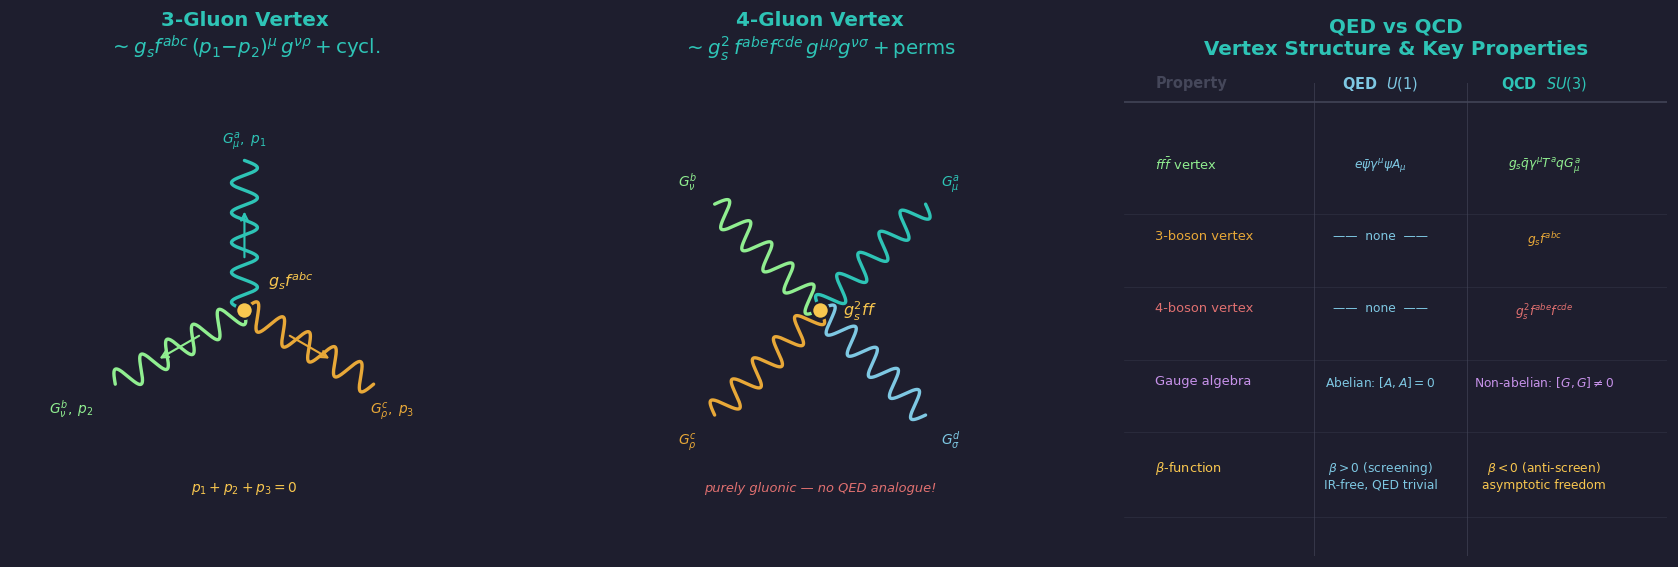

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
fig.patch.set_facecolor(BG)

# ── Gluon (curly) line helper ─────────────────────────────────────────────
def gluon_line(ax, x1, y1, x2, y2, col=TEAL, n_loops=6, lw=2.2, amplitude=0.10):
    """Curly line for gluon propagator. amplitude raised to 0.10 for clear visibility."""
    length = np.hypot(x2-x1, y2-y1)
    if length < 1e-9:
        return
    angle  = np.arctan2(y2-y1, x2-x1)
    t      = np.linspace(0, 1, 500)
    s      = t * length
    perp   = amplitude * np.sin(2*np.pi*n_loops*t)
    xc = x1 + s*np.cos(angle) - perp*np.sin(angle)
    yc = y1 + s*np.sin(angle) + perp*np.cos(angle)
    ax.plot(xc, yc, color=col, lw=lw, solid_capstyle='round')

def vertex_dot(ax, x, y, col=YELLOW, s=120):
    ax.scatter([x], [y], s=s, color=col, zorder=6, edgecolors=BG, linewidth=1.5)

# ── Left: 3-gluon vertex ──────────────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)
ax.set_xlim(-0.3, 3.3)
ax.set_ylim(-0.4, 3.4)
ax.set_aspect('equal')
ax.axis('off')
ax.set_title('3-Gluon Vertex\n' +
             r'$\sim g_s f^{abc}\,(p_1{-}p_2)^\mu\,g^{\nu\rho}+\text{cycl.}$',
             color=TEAL)

cx, cy  = 1.5, 1.5
leg_len = 1.15
vertex_dot(ax, cx, cy)

angles_3  = [90, 210, 330]
colours_3 = [TEAL, GREEN, ORANGE]
labels_3  = [r'$G^a_\mu,\; p_1$', r'$G^b_\nu,\; p_2$', r'$G^c_\rho,\; p_3$']
loff_3    = [(0.0, 0.14), (-0.34, -0.22), (0.14, -0.22)]

for ang, col, lbl, (odx, ody) in zip(angles_3, colours_3, labels_3, loff_3):
    rad = np.deg2rad(ang)
    ex  = cx + leg_len*np.cos(rad)
    ey  = cy + leg_len*np.sin(rad)
    gluon_line(ax, cx, cy, ex, ey, col=col, n_loops=5)
    # Momentum arrow (outward along leg, at mid-point)
    mp  = 0.58
    ax.annotate('',
        xy=(cx+(mp+0.20)*np.cos(rad), cy+(mp+0.20)*np.sin(rad)),
        xytext=(cx+(mp-0.20)*np.cos(rad), cy+(mp-0.20)*np.sin(rad)),
        arrowprops=dict(arrowstyle='->', color=col, lw=1.4, mutation_scale=11))
    ax.text(ex+odx, ey+ody, lbl, color=col, fontsize=9, ha='center')

ax.text(cx, 0.10, r'$p_1 + p_2 + p_3 = 0$',
        ha='center', color=YELLOW, fontsize=9)
ax.text(cx+0.18, cy+0.18, r'$g_s f^{abc}$',
        color=YELLOW, fontsize=10.5, fontweight='bold')

# ── Middle: 4-gluon vertex ────────────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)
ax2.set_xlim(-0.3, 3.3)
ax2.set_ylim(-0.4, 3.4)
ax2.set_aspect('equal')
ax2.axis('off')
ax2.set_title('4-Gluon Vertex\n' +
              r'$\sim g_s^2\,f^{abe}f^{cde}\,g^{\mu\rho}g^{\nu\sigma}+\text{perms}$',
              color=TEAL)

cx2, cy2 = 1.5, 1.5
vertex_dot(ax2, cx2, cy2)

angles_4  = [45, 135, 225, 315]
colours_4 = [TEAL, GREEN, ORANGE, BLUE]
labels_4  = [r'$G^a_\mu$', r'$G^b_\nu$', r'$G^c_\rho$', r'$G^d_\sigma$']
loff_4    = [(0.12, 0.14), (-0.28, 0.14), (-0.28, -0.22), (0.12, -0.22)]

for ang, col, lbl, (odx, ody) in zip(angles_4, colours_4, labels_4, loff_4):
    rad = np.deg2rad(ang)
    ex  = cx2 + leg_len*np.cos(rad)
    ey  = cy2 + leg_len*np.sin(rad)
    gluon_line(ax2, cx2, cy2, ex, ey, col=col, n_loops=5)
    ax2.text(ex+odx, ey+ody, lbl, color=col, fontsize=9)

ax2.text(cx2, 0.10, r'purely gluonic — no QED analogue!',
         ha='center', color=RED, fontsize=8.5, style='italic')
ax2.text(cx2+0.18, cy2-0.05, r'$g_s^2 ff$',
         color=YELLOW, fontsize=10.5, fontweight='bold')

# ── Right: QED vs QCD comparison (full table with all columns) ────────────
ax3 = axes[2]
ax3.set_facecolor(BG)
ax3.set_xlim(-0.3, 5.0)
ax3.set_ylim(-0.3, 5.8)
ax3.axis('off')
ax3.set_title('QED vs QCD\nVertex Structure & Key Properties', color=TEAL)

# Column headers: Property | QED U(1) | QCD SU(3)
COL_PROP = 0.0
COL_QED  = 2.2
COL_QCD  = 3.8
ax3.text(COL_PROP, 5.5, 'Property',      color=EDGE,  fontsize=9.5, fontweight='bold')
ax3.text(COL_QED,  5.5, r'QED  $U(1)$',  color=BLUE,  fontsize=9.5, fontweight='bold', ha='center')
ax3.text(COL_QCD,  5.5, r'QCD  $SU(3)$', color=TEAL,  fontsize=9.5, fontweight='bold', ha='center')
ax3.axhline(5.32, color=EDGE, lw=1.0)

# Vertical dividers
ax3.axvline(1.55, color=EDGE, lw=0.7, alpha=0.6, ymin=0.0, ymax=0.96)
ax3.axvline(3.05, color=EDGE, lw=0.7, alpha=0.6, ymin=0.0, ymax=0.96)

# Rows: (property label, QED value, QCD value, y-position, property colour)
rows_cmp = [
    (r'$ff\bar f$ vertex',
     r'$e\bar\psi\gamma^\mu\psi A_\mu$',
     r'$g_s\bar q\gamma^\mu T^a q G^a_\mu$',
     4.65, GREEN),
    (r'3-boson vertex',
     r'——  none  ——',
     r'$g_s f^{abc}$',
     3.75, ORANGE),
    (r'4-boson vertex',
     r'——  none  ——',
     r'$g_s^2 f^{abe}f^{cde}$',
     2.85, RED),
    (r'Gauge algebra',
     r'Abelian: $[A,A]=0$',
     r'Non-abelian: $[G,G]\neq 0$',
     1.95, PURPLE),
    (r'$\beta$-function',
     r'$\beta>0$ (screening)'+'\n'+'IR-free, QED trivial',
     r'$\beta<0$ (anti-screen)'+'\n'+'asymptotic freedom',
     0.90, YELLOW),
]

for (prop, qed_val, qcd_val, y, col) in rows_cmp:
    ax3.text(COL_PROP, y, prop,    color=col,  fontsize=8.5, va='top')
    ax3.text(COL_QED,  y, qed_val, color=BLUE, fontsize=8,   va='top', ha='center')
    ax3.text(COL_QCD,  y, qcd_val, color=col,  fontsize=8,   va='top', ha='center')
    ax3.axhline(y - 0.72, color=EDGE, lw=0.4, alpha=0.5)

plt.tight_layout(pad=1.8)
save('fig03_yang_mills_vertices.png', fig)


---
## All figures generated

| File | Used in slide |
|------|---------------|
| `figures/ch01/fig01_lorentz_reps.png` | §1.1 · Lorentz Group |
| `figures/ch01/fig02_weyl_dirac_majorana.png` | §1.2 · Dirac Spinors |
| `figures/ch01/fig03_yang_mills_vertices.png` | §1.3 · Yang-Mills |

Copy the `figures/` folder next to `sm_ch01_slides.qmd` before rendering with Quarto.

---
## Download — zip all figures and save to your computer

Run this cell **after** all figures have been generated.  
It compresses the entire `figures/ch01/` folder and triggers a browser download.


In [5]:
import zipfile
import os

# ── 1. Zip all generated figures ──────────────────────────────────────────
ZIP_NAME = 'sm_ch01_figures.zip'
OUTDIR   = 'figures/ch01'

with zipfile.ZipFile(ZIP_NAME, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for fname in sorted(os.listdir(OUTDIR)):
        if fname.endswith('.png'):
            fpath = os.path.join(OUTDIR, fname)
            zf.write(fpath, arcname=fname)
            print(f'  added: {fname}  ({os.path.getsize(fpath)//1024} KB)')

print(f'\nArchive ready: {ZIP_NAME}  ({os.path.getsize(ZIP_NAME)//1024} KB)')

# ── 2. Trigger browser download (Colab only) ──────────────────────────────
try:
    from google.colab import files
    files.download(ZIP_NAME)
    print('Download started — check your browser.')
except ImportError:
    # Running locally: just tell the user where the zip is
    print(f'Not running in Colab.  Zip saved at: {os.path.abspath(ZIP_NAME)}')


  added: fig01_lorentz_reps.png  (200 KB)
  added: fig02_weyl_dirac_majorana.png  (220 KB)
  added: fig03_yang_mills_vertices.png  (177 KB)

Archive ready: sm_ch01_figures.zip  (562 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started — check your browser.
